In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [23]:
df = pd.read_csv('../../data/ushape.csv')

In [24]:
df.head()

,X,Y,class
0,0.031595,0.986988,0.0
1,2.115098,-0.046244,1.0
2,0.882490,-0.075756,0.0
3,-0.055144,-0.037332,1.0
4,0.829545,-0.539321,1.0


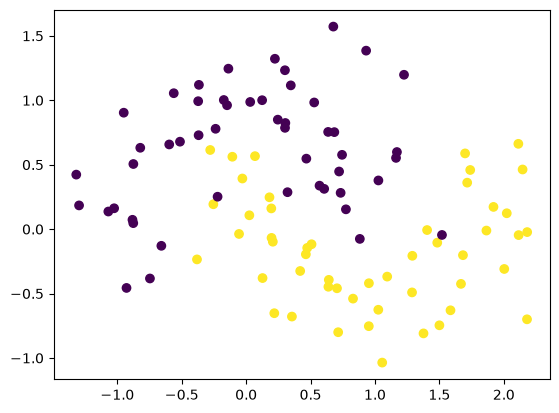

In [25]:
plt.scatter(df['X'],df['Y'],c=df['class'])

In [26]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [27]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [ ]:
model = Sequential()

model.add(Dense(2,activation='relu',input_dim=2))
# model.add(Dense(2,activation='tanh',input_dim=2)) # tanh will also show same behaviour as relu with zero as weight initialization
model.add(Dense(1,activation='sigmoid'))

model.summary()

/home/foolmann/miniconda3/envs/ml312/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9 (36.00 B)

 Trainable params: 9 (36.00 B)

 Non-trainable params: 0 (0.00 B)

In [29]:
# Set parameters to 0
model.get_weights()

[array([[ 1.1013087 , -1.0462395 ],
        [-0.39904726, -1.1522218 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[-0.31295252],
        [ 1.1171097 ]], dtype=float32),
 array([0.], dtype=float32)]

These are default weights and bias 

In [30]:
initial_weights = model.get_weights()

In [31]:
initial_weights[0] = np.zeros(model.get_weights()[0].shape)
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.zeros(model.get_weights()[2].shape)
initial_weights[3] = np.zeros(model.get_weights()[3].shape)

In [32]:
model.set_weights(initial_weights)

In [33]:
model.get_weights()

[array([[0., 0.],
        [0., 0.]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[0.],
        [0.]], dtype=float32),
 array([0.], dtype=float32)]

We overwrite the default weights and bias to zeros

In [34]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [35]:
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100


I0000 00:00:1795364957.936801   18217 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_73742__.8


1/3 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step - accuracy: 0.6250 - loss: 0.6931

I0000 00:00:1795364958.648580   18217 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_73742__.8


3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 338ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5250 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epo

In [36]:
model.get_weights()

[array([[0., 0.],
        [0., 0.]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[0.],
        [0.]], dtype=float32),
 array([-0.00016174], dtype=float32)]

We can see all the weights and bias are still zero so the model will perform terribly 

<Axes: >

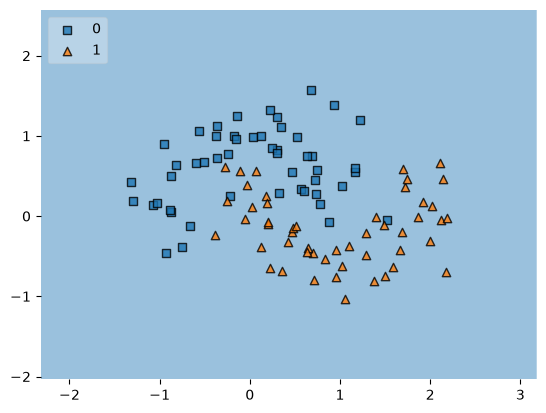

In [37]:
import numpy as np
from mlxtend.plotting import plot_decision_regions

class KerasClassifier:
    def __init__(self, model):
        self.model = model

    def predict(self, X):
        predictions = self.model.predict(X, verbose=0)
        return (predictions.ravel() >= 0.5).astype(int)


# Convert labels to integers
y = y.astype(int)

# Wrap the model
clf = KerasClassifier(model)

# Plot decision regions
plot_decision_regions(X, y, clf=clf, legend=2)

In [38]:
# from mlxtend.plotting import plot_decision_regions
# plot_decision_regions(X,y.astype('int'), clf=model, legend=2)